<div style="display: flex; justify-content: space-between; align-items: flex-start; border-bottom: 2px solid #555555; padding-bottom: 15px; margin-bottom: -8px;">
    <div style="width: 50%;">
        <h2><span style="color: #B30033;">▍</span>TRABAJO DE FIN DE MÁSTER</h2>
        <h1 style="margin-top: -10px;">MARCO DE TRABAJO DE RECOMENDACIÓN DE TALENTO PARA LA FORMACIÓN DE EQUIPOS EN PROYECTOS DE INGENIERÍA DEL SOFTWARE</h1>
    </div>
    <div style="width: 50%; text-align: right;">
        <div style="display: flex; justify-content: space-between; align-items: flex-start; margin-top: 30px;">
            <div style="width: 20%;"></div>
            <div style="width: 80%; border-left: 2px solid #555555; padding-left: 20px;">
                <div style="margin-bottom: 20px;"><p style="margin: 0; font-size: 1.4em; font-weight: bold;">Profesores</p></div>
                <div style="margin-top: 8px; text-align: right;">
                    <span style="display: block; font-size: 1em; color: #D0D0D0;">Aurora Vizcaíno Barceló</span>
                    <span style="display: block; font-size: 1em; color: #D0D0D0; margin-top: 5px;">Julio Alberto López Gómez</span>
                </div>
            </div>
        </div>
    </div>
</div>

<div style="margin-top: 30px; padding: 20px; background-color: rgba(179, 0, 51, 0.05); border-left: 4px solid #B30033; border-radius: 4px;">
    <h3 style="margin-top: 0; color: #B30033;">🎯 Objetivo de esta Libreta (Fase 2: Preparación para minería de reglas — Hard Skills)</h3>
    <p style="font-size: 1.1em; line-height: 1.6; color: #E0E0E0;">
        Partimos del dataset limpio de la Libreta 1 (EDA), con <strong>35.434 candidatos y 33 variables</strong>: 24 variables sustantivas (perfil y experiencia, contexto organizativo, tecnologías multivalor, y enriquecimiento geográfico) más 9 <em>flags</em> de ausencia de datos (<code>_is_missing</code>). El objetivo en esta segunda libreta es realizar la transformación los datos en una <strong>matriz transaccional binaria [0, 1]</strong>, en la que cada fila representará a un candidato, pero cada columna dejará de representar una variable original para representar un <em>ítem</em> concreto (por ejemplo, "domina Python" o "tiene nivel educativo Bachelor's"), tomando el valor 1 si el candidato tiene tal ítem y 0 en caso contrario.
    </p>
    <ul style="font-size: 1.1em; line-height: 1.6; color: #D0D0D0; margin-bottom: 0;">
        <li><strong>Binarización de tecnologías:</strong> las 9 columnas de <code>TECH_COLS</code> + <code>DevType</code>, con un <code>top_n</code> calibrado por columna según su cardinalidad real, no un valor único para todas.</li>
        <li><strong>Discretización de las variables continuas:</strong> Tenemos <code>WorkExp</code>, <code>YearsCode</code>, <code>ToolCountWork</code>, <code>ConvertedCompYearly</code> y las vamos a dividir por intervalos, así evitamos que la imputación por mediana del salario distorsione los cortes.</li>
        <li><strong>One-Hot del resto de categóricas:</strong> aquí incluimos <code>EdLevel</code>/<code>RemoteWork</code>/<code>OrgSize</code>/<code>Industry</code>, mapeadas de vuelta a un texto legible para nosotros que más adelante vamos a binarizar.</li>
        <li><strong>Exclusión deliberada</strong> de la variable <code>Country</code> que corresponde a los países debido a su elevada cardinalidad, por lo que la reservamos para el matching, al igual que <code>Zonas_Horarias.</code></li>
    </ul>
</div>

<div style="border-bottom: 2px solid #555555; padding-bottom: 25px; margin-bottom: 10px">
    <div style="display: flex; align-items: center; margin-bottom: 10px;">
        <span style="color: #B30033; font-size: 1.5em; margin-right: 10px;">▍</span>
        <h3 style="margin: 0; font-size: 1.4em; font-weight: bold">
            Realizado por Miguel Ángel Sánchez-Medina Camacho <span style="font-size: 0.7em; font-style: italic; font-weight: normal;"></span>
        </h3>
    </div>
</div>

### 2.1. Configuración y carga de datos limpios

Primero de todo, importamos las librerías para tratar los datos (`pandas`, `numpy`). Posteriormente, cargamos el dataset que generamos con los datos limpios de la libreta anterior sin duplicados ni nulos estructurales, tratados mediante indicadores de ausencia y perfiles inconsistentes (ej. `WorkExp` superior a `YearsCode`).

In [1]:
import os
import sys
import warnings

sys.path.append(os.path.abspath(os.path.join('../..')))

from src.hard_skills import config
from src.hard_skills import utils

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno
from sklearn import set_config
from IPython.display import display

random_state = seed = 42
warnings.filterwarnings("ignore")
set_config(transform_output="pandas")

In [2]:
df_feature_engineering_hard = pd.read_csv(
    config.PROCESSED_EDA_PATH, index_col='CandidateId', low_memory=False,
    keep_default_na=False, na_values=['']
)

print(f"Dimensiones dataset: {df_feature_engineering_hard.shape}")
display(df_feature_engineering_hard.head(5))

Dimensiones dataset: (35434, 33)


,EdLevel,Employment,WorkExp,YearsCode,DevType,OrgSize,ICorPM,RemoteWork,Industry,ToolCountWork,...,YearsCode_is_missing,ToolCountWork_is_missing,JobSat_is_missing,ConvertedCompYearly_is_missing,EdLevel_is_missing,RemoteWork_is_missing,OrgSize_is_missing,Industry_is_missing,Continente,Zonas_Horarias
CandidateId,,,,,,,,,,,,,,,,,,,,,
0,6.0,Employed,8.0,14.0,"Developer, mobile",3.0,People manager,5.0,3.0,7.0,...,0,0,0,0,0,0,0,0,Europe,"Europe/Simferopol, Europe/Kyiv"
1,4.0,Employed,2.0,10.0,"Developer, back-end",5.0,Individual contributor,4.0,7.0,6.0,...,0,0,0,0,0,0,0,0,Europe,Europe/Amsterdam
2,5.0,"Independent contractor, freelancer, or self-em...",10.0,12.0,"Developer, front-end",NaN,None,NaN,1.0,3.0,...,0,0,0,0,0,1,1,0,Europe,"Europe/Simferopol, Europe/Kyiv"
3,5.0,Employed,4.0,5.0,"Developer, back-end",8.0,Individual contributor,5.0,7.0,NaN,...,0,1,0,0,0,0,0,0,Europe,"Europe/Simferopol, Europe/Kyiv"
4,6.0,"Independent contractor, freelancer, or self-em...",21.0,22.0,Engineering manager,NaN,None,NaN,1.0,4.0,...,0,0,0,0,0,1,1,0,Europe,"Europe/Simferopol, Europe/Kyiv"


### 2.2. Análisis de datos actuales

Antes de transformar los datos vamos a echarles un vistazo rápido con `.info()` para conocer bien lo que tenemos hasta este punto. Con este comando vamos a ver de forma más rápida el porcentaje de información que falta en cada variable y también separamos las columnas en categóricas, continuas o binarias. Este paso muy simple me viene bien para así poder diseñar a lo largo de la libreta un pipeline más limpio.

In [3]:
df_feature_engineering_hard.info()

<class 'pandas.DataFrame'>
RangeIndex: 35434 entries, 0 to 35433
Data columns (total 33 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   EdLevel                         35359 non-null  float64
 1   Employment                      35434 non-null  str    
 2   WorkExp                         33953 non-null  float64
 3   YearsCode                       34643 non-null  float64
 4   DevType                         35434 non-null  str    
 5   OrgSize                         29798 non-null  float64
 6   ICorPM                          35434 non-null  str    
 7   RemoteWork                      19852 non-null  float64
 8   Industry                        29359 non-null  float64
 9   ToolCountWork                   22965 non-null  float64
 10  Country                         35434 non-null  str    
 11  LanguageHaveWorkedWith          35434 non-null  str    
 12  DatabaseHaveWorkedWith          35434 non-n

### 2.3. Limpieza estructural e identificación de nulos

Para poder seguir, vamos a ver con más detalle la estructura del dataset. En esta celda vemos los **tipos de datos**, viendo cuantas variables tenemos de cada tipo y así poder continuar con la estrategia de transformación. También vamos a ver el **porcentaje de nulos** exacto por columna.

Con todo esto, nos es más fácil identificar qué variables superan un umbral crítico de nulos, algo muy importante para poder diseñar un pipeline de limpieza seguro y evitando ruido innecesario.

In [4]:
print("\nTipos de datos presentes:")
display(df_feature_engineering_hard.dtypes.value_counts())

print("\nTop 30 de variables con mayor porcentaje de valores nulos:")
null_pct = (df_feature_engineering_hard.isna().mean()*100).sort_values(ascending=False)
display(null_pct.head(30).to_frame("null_pct"))


Tipos de datos presentes:


str        15
float64     9
int64       9
Name: count, dtype: int64


Top 30 de variables con mayor porcentaje de valores nulos:


,null_pct
RemoteWork,43.974714
ToolCountWork,35.189366
JobSat,30.620308
Zonas_Horarias,18.882994
Industry,17.144550
OrgSize,15.905627
WorkExp,4.179602
YearsCode,2.232319
EdLevel,0.211661
ICorPM,0.000000


### 2.4 Clasificación de variables según su tipo

Ahora que tenemos bien conocidos los nulos presentes, vamos a dividir el dataset según el tipo de variable. Cada tipo de variable requiere que se realice un tratamiento específico para llegar al formato transaccional binario el cual es nuestro objetivo, por lo que no podemos aplicar las mismas transformaciones a todo el conjunto de datos.

En esta celda iteramos sobre las columnas para clasificarlas automáticamente en tres tipos:
1. **Variables Categóricas (`object`, `category`):** Textos complejos (como las listas de tecnologías) que requerirán técnicas de *parsing* y binarización.
2. **Variables Binarias:** Aquellas que ya son puramente `[0, 1]` o `[True, False]`. No requieren transformación adicional, ya están en formato que estamos buscando.
3. **Variables Continuas:** Valores numéricos con mayor rango (como años de experiencia) que debemos discretizar en bins antes de poder usarse como ítems.

In [5]:
columnas_objetivo = df_feature_engineering_hard.select_dtypes(include=["object", "category"]).columns.tolist()
numericas = df_feature_engineering_hard.select_dtypes(include=[np.number, "bool"]).columns.tolist()
binary_cols = []
continuous_cols = []

for c in numericas:
    if c in config.CAT_COLS_MAPPED:
        continue
    vals = pd.Series(df_feature_engineering_hard[c].dropna().unique())
    if len(vals) <= 2 and set(vals.tolist()).issubset({0, 1, True, False}):
        binary_cols.append(c)
    else:
        continuous_cols.append(c)

categoricas = columnas_objetivo.copy() + config.CAT_COLS_MAPPED

print("Variables continuas:", len(continuous_cols))
display(continuous_cols)
print("Variables binarias:", len(binary_cols))
display(binary_cols)
print("Variables categóricas:", len(categoricas))
display(categoricas)

Variables continuas: 5


['WorkExp', 'YearsCode', 'ToolCountWork', 'ConvertedCompYearly', 'JobSat']

Variables binarias: 9


['WorkExp_is_missing',
 'YearsCode_is_missing',
 'ToolCountWork_is_missing',
 'JobSat_is_missing',
 'ConvertedCompYearly_is_missing',
 'EdLevel_is_missing',
 'RemoteWork_is_missing',
 'OrgSize_is_missing',
 'Industry_is_missing']

Variables categóricas: 19


['Employment',
 'DevType',
 'ICorPM',
 'Country',
 'LanguageHaveWorkedWith',
 'DatabaseHaveWorkedWith',
 'PlatformHaveWorkedWith',
 'WebframeHaveWorkedWith',
 'DevEnvsHaveWorkedWith',
 'OpSysProfessional use',
 'OfficeStackAsyncHaveWorkedWith',
 'CommPlatformHaveWorkedWith',
 'AIModelsHaveWorkedWith',
 'Continente',
 'Zonas_Horarias',
 'EdLevel',
 'RemoteWork',
 'OrgSize',
 'Industry']

### 2.5 Validación visual de la matriz (post-limpieza)

Ahora realizamos una comprobación visual definitiva sobre las variables numéricas utilizando `missingno`. 

Con este gráfico de matriz podemos ver de un solo vistazo que la integridad estructural del dataset es sólida y densa, lo que nos permite demostrar que hemos eliminado los valores perdidos críticos, el requisito indispensable para garantizar que las transformaciones posteriores (discretización, binarización) produzcan una matriz transaccional coherente, sin ítems corruptos ni ruido introducido por datos faltantes mal gestionados.

<Figure size 1000x500 with 0 Axes>

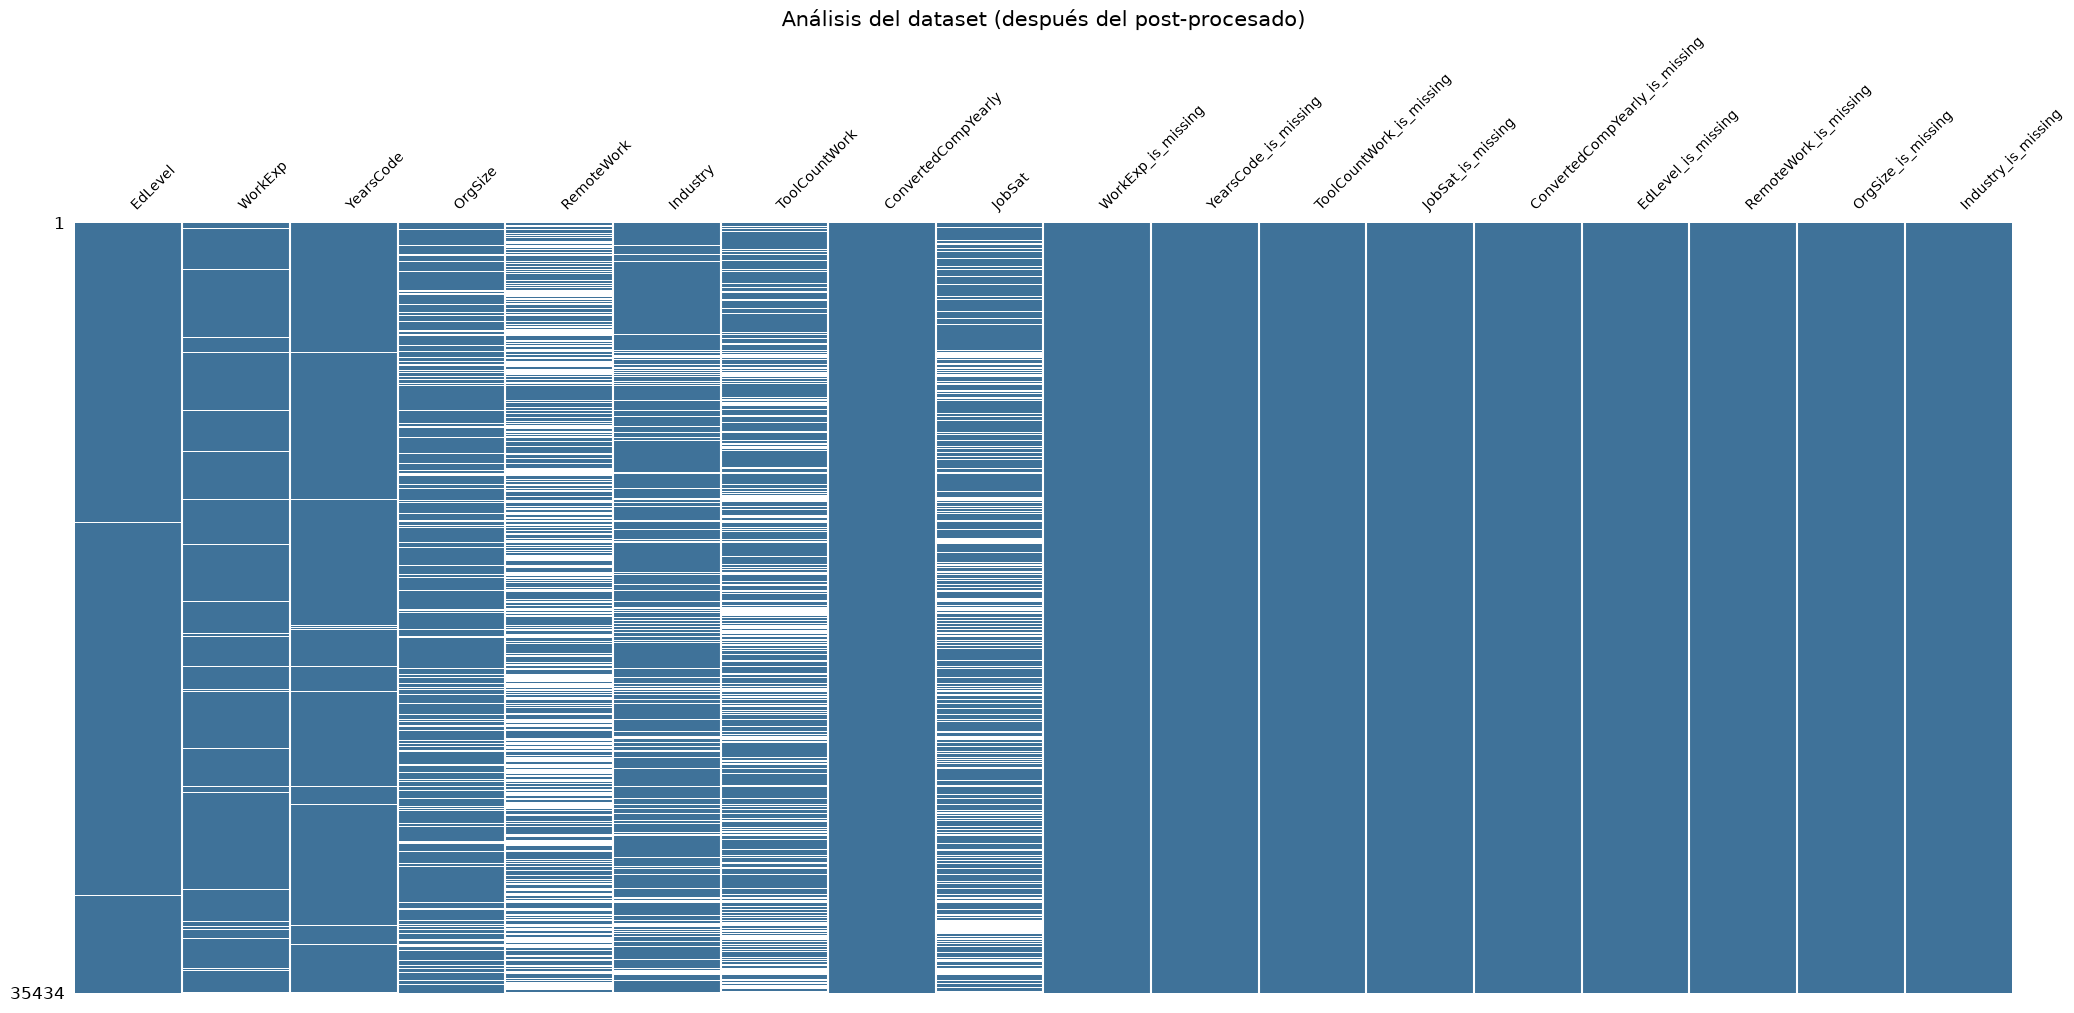

In [6]:
df_numericas = df_feature_engineering_hard.select_dtypes(include=[np.number])

plt.figure(figsize=(10, 5))
msno.matrix(df_numericas, sparkline=False, fontsize=10, color=(0.25, 0.45, 0.6))
plt.title("Análisis del dataset (después del post-procesado)", fontsize=15)
plt.show()

Como hemos comentado, la columna de las tecnologías va a ser complicada de binarizar. Para poder decidir como hacerlo, primero vamos a ver el contenido real de una de ellas para que represente al resto. El objetivo aquí es simplemente confirmar de primera mano el formato exacto que siguen los datos en esta columna, viendo los separadores, valores vaciós o que inconsistencias pueden tener, antes de poder construir cualquier lógica de procesamiento sobre estos.

In [7]:
print(df_feature_engineering_hard['LanguageHaveWorkedWith'].dropna().head(10).tolist())

['Bash/Shell (all shells);Dart;SQL', 'Java', 'Dart;HTML/CSS;JavaScript;TypeScript', 'Java;Kotlin;SQL', 'C;C#;C++;Delphi;HTML/CSS;Java;JavaScript;Lua;PowerShell;Python;SQL;TypeScript;VBA;Visual Basic (.Net)', 'Java;Scala', 'JavaScript;TypeScript', 'Bash/Shell (all shells);HTML/CSS;JavaScript;Python;SQL;TypeScript', 'Java;Python;Scala', 'None']


En la celda de antes hemos visto que la columna se puede separar en tokens individuales con `split(';')` y `explode()`, así contaremos cuántos valores realmente distintos puede contener. Después, comparamos el recuento de valores únicos con y sin eliminar los espacios en blanco sobrantes, esto porque en un espacio de más alrededor de un token podría hacer que por ejemplo `"Java"` y `"Java "` se contabilizaran como dos tecnologías diferentes, inflando artificialmente el número de categorías.

In [8]:
serie = df_feature_engineering_hard['LanguageHaveWorkedWith'].dropna()
tokens_raw = serie.str.split(';').explode()

print("Tokens únicos con los espacios:", tokens_raw.nunique())
print("Tokens únicos sin los espacios:", tokens_raw.str.strip().nunique())
print()
print("Tokens con espacios de más:")
print(tokens_raw[tokens_raw != tokens_raw.str.strip()].head(10).tolist())

Tokens únicos con los espacios: 43
Tokens únicos sin los espacios: 43

Tokens con espacios de más:
[]


### 2.6. Parseo y binarización de los datos

Las respuestas de la encuesta agrupan los lenguajes, bases de datos y plataformas en una sola cadena de texto separada por caracteres especiales (ej. `Python;SQL;AWS`).

En este bloque se aplica la función personalizada `codificar_multilabel` de `utils.py` para realizar un *parsing* avanzado y desglosar estas cadenas. Con ella, cada tecnología se transforma en una nueva columna independiente mediante una **binarización estricta [0, 1]** (1 si el candidato la domina, 0 si no).

*Nota de calibración:* se calcula el número real de valores únicos de cada columna, y se decide el `top_n` en consecuencia: si la columna tiene **15 o menos valores reales, se conservan todos** (como ocurre con `OpSysProfessional use`, que se queda con sus 15 valores completos). Por otro lado, si supera ese umbral, se limita a las **20 categorías más frecuentes**, evitando así una explosión de dimensionalidad que aportaría ruido innecesario a las reglas de asociación posteriores.

In [9]:
tech_cols = config.TECH_COLS+['DevType']

for col in tech_cols:
    if col in df_feature_engineering_hard.columns:
        listas = df_feature_engineering_hard[col].fillna('').apply(lambda x: [v.strip() for v in str(x).split(';') if v.strip() and v.strip().lower()!= 'none'])
        n_valores = listas.explode().nunique()
        top_n_calibrado = n_valores if n_valores <= 15 else 20

        print(f"{col}: {n_valores} valores únicos reales -> top_n={top_n_calibrado}")
        df_feature_engineering_hard = utils.codificar_multilabel(df_feature_engineering_hard, col, top_n=top_n_calibrado)

print(f"\nTecnologías transformadas en binarios, establecen un total de {df_feature_engineering_hard.shape} nuevas dimensiones")

LanguageHaveWorkedWith: 42 valores únicos reales -> top_n=20
DatabaseHaveWorkedWith: 30 valores únicos reales -> top_n=20
PlatformHaveWorkedWith: 42 valores únicos reales -> top_n=20
WebframeHaveWorkedWith: 28 valores únicos reales -> top_n=20
DevEnvsHaveWorkedWith: 27 valores únicos reales -> top_n=20
CommPlatformHaveWorkedWith: 18 valores únicos reales -> top_n=20
OfficeStackAsyncHaveWorkedWith: 25 valores únicos reales -> top_n=20
OpSysProfessional use: 15 valores únicos reales -> top_n=15
AIModelsHaveWorkedWith: 17 valores únicos reales -> top_n=20
DevType: 29 valores únicos reales -> top_n=20

Tecnologías transformadas en binarios, establecen un total de (35434, 213) nuevas dimensiones


Finalmente, ya podemos estar seguros de que `LanguageHaveWorkedWith` contiene 42 valores únicos reales, sin importar si contamos o no contamos los espacios. Esto nos confirma dos cosas importantes: en primer lugar, vemos que el separador `;` y el formato de los datos crudos son correctos y no requieren ninguna limpieza adicional.

Con esta confirmación, procedemos a binarizar todas las columnas de tecnologías mediante `codificar_multilabel()`

### 2.7. Purga de variables y codificación One-Hot

En esta celda vamos a afinar aún más nuestro conjunto de datos antes de pasar a la extracción profunda de tecnologías. Para esta sección haremos lo siguiente:

1. **Eliminación de ruido y sesgos:** Vamos a descartar todas aquellas columnas que no nos sirven, como por ejemplo `Zonas_Horarias` ( en este caso se explica por su altísimo nivel de nulos).

2. **One-Hot Encoding:** Para todas aquellas variables categóricas nominales con valores muy altos, como puede ser el tipo de empleo o si el perfil es *Individual Contributor* o *People Manager*, aplicaremos la función `get_dummies`. Esta función expande cada categoría en nuevas columnas que son totalmente independientes y binarizadas, manteniendo todo estrictamente con el formato que buscamos de manera homogénea.

In [10]:
cols_to_drop = ['Country', 'Zonas_Horarias']
df_feature_engineering_hard = df_feature_engineering_hard.drop(columns=[col for col in cols_to_drop if col in df_feature_engineering_hard.columns])

inv_ed_map = {v: k for k, v in config.ED_LEVEL_MAPPING.items() if v != 0}
inv_remote_map = {v: k for k, v in config.MAPEO_MODALIDADES.items()}
inv_org_map = {v: k.replace(' employees', '') for k, v in config.ORG_SIZE_MAPPING.items() if v != 0}
inv_industry_map = {}


for k, v in config.INDUSTRY_MAPPING.items():
    if v not in inv_industry_map and v != 0:
        inv_industry_map[v] = k

df_feature_engineering_hard['EdLevel'] = df_feature_engineering_hard['EdLevel'].map(inv_ed_map)
df_feature_engineering_hard['RemoteWork'] = df_feature_engineering_hard['RemoteWork'].map(inv_remote_map)
df_feature_engineering_hard['OrgSize'] = df_feature_engineering_hard['OrgSize'].map(inv_org_map)
df_feature_engineering_hard['Industry'] = df_feature_engineering_hard['Industry'].map(inv_industry_map)

col_nominal = ['Employment','ICorPM',  'Continente','EdLevel', 'RemoteWork', 'OrgSize','Industry']
col_presentes = [col for col in col_nominal if col in df_feature_engineering_hard.columns]
df_feature_engineering_hard = pd.get_dummies(df_feature_engineering_hard, columns=col_presentes, dtype=int)

col_triviales = [c for c in df_feature_engineering_hard.columns if c.endswith('_None')]
df_feature_engineering_hard = df_feature_engineering_hard.drop(columns=col_triviales)
print(f"Columnas triviales '_None' eliminadas: {len(col_triviales)}")
print(f"Dimensiones despues de aplicar One-Hot: {df_feature_engineering_hard.shape}")

Columnas triviales '_None' eliminadas: 1
Dimensiones despues de aplicar One-Hot: (35434, 248)


Para poder discretizar las variables continuas correctamente, primero vamos a ver la distribución de estas variables, sus medias, cuartiles, mínimos, máximos, percentiles... para ello emplearemos `describe()`, con el cual calibraremos los tramos con criterio.
También vamos a comprobar el porcentaje de valores faltantes, esta vez a partir de los flags`_is_missing` generados en la Libreta 1.

In [11]:
cols_continuas = ['WorkExp', 'YearsCode', 'ToolCountWork', 'ConvertedCompYearly']
display(df_feature_engineering_hard[cols_continuas].describe())

print("\n% de missing (según los flags, no según NaN actual):")
for col in cols_continuas:
    flag = f'{col}_is_missing'
    if flag in df_feature_engineering_hard.columns:
        print(f"{col}: {df_feature_engineering_hard[flag].mean()*100:.1f}%")

,WorkExp,YearsCode,ToolCountWork,ConvertedCompYearly
count,33953.000000,34643.000000,22965.000000,35434.000000
mean,12.907372,17.558352,14.887742,84656.193486
std,9.871285,11.107201,209.390939,53405.191340
min,1.000000,1.000000,0.000000,10000.000000
25%,5.000000,9.000000,4.000000,65663.000000
50%,10.000000,15.000000,6.000000,75320.000000
75%,19.000000,25.000000,10.000000,88197.750000
max,65.000000,65.000000,10000.000000,300000.000000



% de missing (según los flags, no según NaN actual):
WorkExp: 4.2%
YearsCode: 2.2%
ToolCountWork: 35.2%
ConvertedCompYearly: 40.6%


### 2.8. Discretización de variables continuas

Antes de iniciar el proceso de discretización, se revisa la distribución real y el porcentaje de valores ausentes que ya se vieron en la celda anterior, ya que estos datos sirven para calibrar mejor los tramos. Las reglas de asociación no operan sobre valores numéricos continuos, por lo que las variables `WorkExp`, `YearsCode`, `ToolCountWork`, `ConvertedCompYearly` y `JobSat` se convierten en tramos o intervalos, similares a los aplicados para las soft skills.

Un caso especial es el de `ConvertedCompYearly`: dado que sus valores nulos se imputaron con la mediana salarial en la Libreta 1, a los candidatos marcados con `ConvertedCompYearly_is_missing=1` **no se les asigna ningún tramo real**, para no contaminar las reglas de asociación con un valor de salario inventado.

In [12]:
def bin_workexp(x):
    if pd.isna(x): workexp = np.nan
    elif x < 5: workexp = '<5 (Junior)'
    elif x < 10: workexp = '5-9 (Semi-Senior o Mid)'
    elif x < 19: workexp = '10-18 (Senior)'
    else: workexp = '>=19 (Muy Senior)'
    return workexp

def bin_yearscode(x):
    if pd.isna(x): yearscode = np.nan
    elif x < 9: yearscode = '<9'
    elif x < 15: yearscode = '9-14'
    elif x < 25: yearscode = '15-24'
    else: yearscode = '>=25'
    return yearscode

def bin_toolcount(x):
    if pd.isna(x): toolcount = np.nan
    elif x <= 4: toolcount = '<=4'
    elif x <= 10: toolcount = '5-10'
    elif x <= 20: toolcount = '11-20'
    else: toolcount = '>20'
    return toolcount

def bin_salario(row):
    if row['ConvertedCompYearly_is_missing'] == 1:
        sueldoanual = np.nan  # imputado con la mediana
    else:
        x = row['ConvertedCompYearly']
        if x < 40000: sueldoanual = '<40k'
        elif x < 70000: sueldoanual = '40-70k'
        elif x < 100000: sueldoanual = '70-100k'
        elif x < 150000: sueldoanual = '100-150k'
        else: sueldoanual = '>150k'
    return sueldoanual

def bin_jobsat(x):
    if pd.isna(x): satisfaciontrabajo = np.nan
    elif x <= 5: satisfaciontrabajo = 'Baja (0-5)'
    elif x <= 7: satisfaciontrabajo = 'Media (6-7)'
    else: satisfaciontrabajo = 'Alta (8-10)'
    return satisfaciontrabajo

df_feature_engineering_hard['ToolCountWork'] = df_feature_engineering_hard['ToolCountWork'].clip(upper=50)
df_feature_engineering_hard['WorkExp_Bin'] = df_feature_engineering_hard['WorkExp'].apply(bin_workexp)
df_feature_engineering_hard['YearsCode_Bin'] = df_feature_engineering_hard['YearsCode'].apply(bin_yearscode)
df_feature_engineering_hard['ToolCountWork_Bin'] = df_feature_engineering_hard['ToolCountWork'].apply(bin_toolcount)
df_feature_engineering_hard['ConvertedCompYearly_Bin'] = df_feature_engineering_hard.apply(bin_salario, axis=1)
df_feature_engineering_hard['JobSat_Bin'] = df_feature_engineering_hard['JobSat'].apply(bin_jobsat)

for col in ['WorkExp_Bin', 'YearsCode_Bin', 'ToolCountWork_Bin', 'ConvertedCompYearly_Bin', 'JobSat_Bin']:
    print(f"\n{col}:")
    print(df_feature_engineering_hard[col].value_counts(dropna=False))


WorkExp_Bin:
WorkExp_Bin
10-18 (Senior)             10026
>=19 (Muy Senior)           8701
5-9 (Semi-Senior o Mid)     7772
<5 (Junior)                 7454
NaN                         1481
Name: count, dtype: int64

YearsCode_Bin:
YearsCode_Bin
15-24    9177
>=25     9155
<9       8224
9-14     8087
NaN       791
Name: count, dtype: int64

ToolCountWork_Bin:
ToolCountWork_Bin
NaN      12469
5-10     12336
<=4       6130
11-20     3488
>20       1011
Name: count, dtype: int64

ConvertedCompYearly_Bin:
ConvertedCompYearly_Bin
NaN         14393
<40k         5068
40-70k       4502
70-100k      3999
100-150k     3822
>150k        3650
Name: count, dtype: int64

JobSat_Bin:
JobSat_Bin
Alta (8-10)    12448
NaN            10850
Media (6-7)     8172
Baja (0-5)      3964
Name: count, dtype: int64


### 2.9. Ensamblaje final de la matriz transaccional

Ahora que ya contamos con las variables continuas bien discretizadas, vamos a aplicar un One-Hot Enconding sobre los bins que tenemos de resultados y eliminamos las columnas que teníamos originalmente por sus versiones de tipo categóricas. Después, vamos a verificar que la matriz sea estrictamente binaria, ya que cualquier columna con más de dos valores únicos nos mostraría que una variable se quedó sin discretizar.

In [13]:
df_feature_engineering_hard = pd.get_dummies(df_feature_engineering_hard, columns=['WorkExp_Bin','YearsCode_Bin','ToolCountWork_Bin','ConvertedCompYearly_Bin'],dtype=int, dummy_na=False)

cols_continuas_crudas = ['WorkExp','YearsCode', 'ToolCountWork','ConvertedCompYearly']
df_matriz_hard = df_feature_engineering_hard.drop(columns=[c for c in cols_continuas_crudas 
                                                           if c in df_feature_engineering_hard.columns])

print(f"Dimensiones finales de la matriz: {df_matriz_hard.shape}")
tipos_no_binarios = [c for c in df_matriz_hard.columns 
                     if df_matriz_hard[c].dropna().nunique() > 2]

print(f"Columnas no binarias residuales (aqui el objetivo es que sea 0): {len(tipos_no_binarios)}")
if tipos_no_binarios:
    print(tipos_no_binarios)

display(df_matriz_hard.head(5))

Dimensiones finales de la matriz: (35434, 262)
Columnas no binarias residuales (aqui el objetivo es que sea 0): 2
['JobSat', 'JobSat_Bin']


,JobSat,WorkExp_is_missing,YearsCode_is_missing,ToolCountWork_is_missing,JobSat_is_missing,ConvertedCompYearly_is_missing,EdLevel_is_missing,RemoteWork_is_missing,OrgSize_is_missing,Industry_is_missing,...,YearsCode_Bin_>=25,ToolCountWork_Bin_11-20,ToolCountWork_Bin_5-10,ToolCountWork_Bin_<=4,ToolCountWork_Bin_>20,ConvertedCompYearly_Bin_100-150k,ConvertedCompYearly_Bin_40-70k,ConvertedCompYearly_Bin_70-100k,ConvertedCompYearly_Bin_<40k,ConvertedCompYearly_Bin_>150k
CandidateId,,,,,,,,,,,,,,,,,,,,,
0,10.0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
1,9.0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,1,0,0,0,0
2,8.0,0,0,0,0,0,0,1,1,0,...,0,0,0,1,0,0,1,0,0,0
3,6.0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
4,7.0,0,0,0,0,0,0,1,1,0,...,0,0,0,1,0,0,1,0,0,0


En esta celda vamos a hacer el último paso del ensamblaje de la matriz convirtiendo la categoría de satisfacción laboral `JobSat` en columnas binarias, eliminando la columna original que ya no necesitamos. Después, verificamos que todo el dataframe quede totalmente binarizado y no haya columnas residuales

In [14]:
df_matriz_hard = pd.get_dummies(df_matriz_hard, columns=['JobSat_Bin'],dtype=int, dummy_na=False)
df_matriz_hard = df_matriz_hard.drop(columns=['JobSat'])

tipos_no_binarios = [c for c in df_matriz_hard.columns 
                     if df_matriz_hard[c].dropna().nunique() > 2]

print(f"Columnas no binarias residuales (aqui el objetivo es que sea 0): {len(tipos_no_binarios)}")

Columnas no binarias residuales (aqui el objetivo es que sea 0): 0


### 2.10. Exportación de la matriz transaccional

Ahora que ya tenemos la matriz transaccional lista para los siguientes pasos, exportamos a `data/processed/matriz_transaccional_hard.csv` de igual manera que se hizo para las soft skills. El objetivo de esto es evitar realizar de nuevo la ejecución de estos pasos para poder alimentar constantemente a los algoritmos de minería de reglas de asociación que aplicaremos en la tercera libreta de model training.

In [15]:
df_matriz_hard.to_csv(config.MATRIZ_TRANSACCIONAL_PATH, index=True, index_label='CandidateId')
print(f"Matriz guardada en: {config.MATRIZ_TRANSACCIONAL_PATH}")
print(f"Dimensiones finales: {df_matriz_hard.shape}")

Matriz guardada en: /run/media/miguel-angel/Datos compartidos/TFM/data/processed/hard_skills/matriz_transaccional_hard.csv
Dimensiones finales: (35434, 263)


### 2.11. Resumen final de la libreta

Después de realizar todo el proceso de ingeniería de características, nuestro resultado final para pasar a la fase del model training queda compuesto por **35.434 candidatos y 263 columnas-ítem binarias**. Vamos a hacer un desglose por categorías:

| Categoría | Nº de columnas |
|---|---|
| Tecnologías (`LanguageHaveWorkedWith`, `DatabaseHaveWorkedWith`, `PlatformHaveWorkedWith`, `WebframeHaveWorkedWith`, `DevEnvsHaveWorkedWith`, `CommPlatformHaveWorkedWith`, `OfficeStackAsyncHaveWorkedWith`, `OpSysProfessional use`, `AIModelsHaveWorkedWith`, `DevType`) | **190** |
| Categóricas ordinales/nominales (`EdLevel`, `RemoteWork`, `OrgSize`, `Industry`, `Employment`, `ICorPM`) | **48** |
| Continuas discretizadas (`WorkExp_Bin`, `YearsCode_Bin`, `ToolCountWork_Bin`, `ConvertedCompYearly_Bin`, `JobSat_Bin`) | **20** |
| Flags de ausencia de datos (`_is_missing`) | **9** |
| **Total** | **263** |

Como era de esperar, las variables de **tecnología dominan la matriz** (190 de 263 columnas, un 72,2% del total), que se explica por que 10 de las 24 variables sustantivas originales son multivalor, y cada una se descompone en varias columnas-ítem tras la calibración. Para el resto de categorías (categóricas, continuas, flags) aporta una proporción mucho menor, pero son muy necesarias para capturar el contexto organizativo y la trazabilidad de los datos ausentes en las reglas de asociación posteriores.